# Notebook setup

Setup Qt for interactive viewing in this notebook

In [1]:
%gui qt

Define the locations of source data and results

In [2]:
DATAPATH = "C:\\Users\\md1spsx\\Documents\\Data\\case_studies\\source\\lung_dce"
BUILD_PATH = "C:\\Users\\md1spsx\\Documents\\Data\\case_studies\\results\\lung_dce"

import os

IMAGEPATH = os.path.join(BUILD_PATH, 'images')
CHECKPOINTSPATH = os.path.join(BUILD_PATH, 'checkpoints')
os.makedirs(IMAGEPATH, exist_ok=True)
os.makedirs(CHECKPOINTSPATH, exist_ok=True)

resultspath = os.path.join(BUILD_PATH, 'dicom')
SUBJ = 'SheffieldSubject'
DATA = [resultspath, SUBJ, 'Data']
MAPS = [resultspath, SUBJ, 'Maps']
MASKS = [resultspath, SUBJ, 'Masks']

# Step 1: Data cleaning

Harmonize the DICOM data, saving the results in the build folder

In [ ]:
from case_studies.lung_dce import harmonize_data

harmonize_data(DATAPATH, DATA)

Inspect the 4D source data

In [ ]:
from case_studies.lung_dce import view_dce_notebook

view_dce_notebook(DATA)

# Step 2: Image segmentation

Compute some descriptive maps that can be used as a basis for segmentation

In [ ]:
from case_studies.lung_dce import compute_descriptive_maps

compute_descriptive_maps(DATA, MAPS)

Autosegment the lungs using TotalSegmentator

In [ ]:
from case_studies.lung_dce import autosegment_lungs

autosegment_lungs(MAPS, MASKS)

Check the masks and edit interactively, if needed

In [ ]:
from case_studies.lung_dce import edit_autosegmented_lungs_notebook

edit_autosegmented_lungs_notebook(MAPS, MASKS)

Draw the region of interest for the arterial input function

In [ ]:
from case_studies.lung_dce import draw_arterial_inputs_notebook

draw_arterial_inputs_notebook(MAPS, MASKS)

# Step 3: Breathing motion correction

Motion-correct the VFA data for signal calibration

In [ ]:
from case_studies.lung_dce import vfa_motion_correction

vfa_motion_correction(DATA, MAPS)

Check the motion-corrected VFA data

In [ ]:
from case_studies.lung_dce import view_vfa_notebook

view_vfa_notebook(MAPS)

Perform DCE motion correction

*Note* this is actually a dummy function for this demo which just creates a copy. Motion correction takes a long time and these breath hold data don't need it, so in this case it can be safely skipped.

In [ ]:
from case_studies.lung_dce import dce_motion_correction

dce_motion_correction(DATA, MAPS)

# Step 4: Signal calibration

Fit the VFA data to derive T1 and S0 maps

In [ ]:
from case_studies.lung_dce import vfa_fit

vfa_fit(MAPS)

Align VFA and DCE data, computing also proper scaling factors for the signal intensities.

In [ ]:
from case_studies.lung_dce import align_vfa_with_dce

align_vfa_with_dce(MAPS, MASKS)

# Step 5: Parameter reconstruction with dcmri

Now we have everything in place to model the data and derive the parameters of interest.

Model-based whole-lung analysis

In [ ]:
from case_studies.lung_dce import roi_analysis_model_based

roi_analysis_model_based(MAPS, MASKS, IMAGEPATH)

In [ ]:
from case_studies.lung_dce import view_png

png = os.path.join(IMAGEPATH, f'model_based_lung_left_edited.png')
view_png(png)
png = os.path.join(IMAGEPATH, f'model_based_lung_right_edited.png')
view_png(png)

Model-free whole-lung analysis

In [ ]:
from case_studies.lung_dce import roi_analysis_model_free

roi_analysis_model_free(MAPS, MASKS, IMAGEPATH)

In [ ]:
from case_studies.lung_dce import view_png

png = os.path.join(IMAGEPATH, f'model_free_lung_right_edited.png')
view_png(png)
png = os.path.join(IMAGEPATH, f'model_free_lung_left_edited.png')
view_png(png)

Pixel-by-pixel model-free analysis

In [ ]:
from case_studies.lung_dce import pixel_analysis_model_free

pixel_analysis_model_free(MAPS, MASKS, IMAGEPATH)

In [ ]:
from case_studies.lung_dce import view_png

png = os.path.join(IMAGEPATH, f'Fb_model_free.png')
view_png(png)
png = os.path.join(IMAGEPATH, f've_model_free.png')
view_png(png)

Pixel-by-pixel model-based analysis

In [ ]:
from case_studies.lung_dce import pixel_analysis_model_based

pixel_analysis_model_based(MAPS, MASKS, IMAGEPATH, CHECKPOINTSPATH)

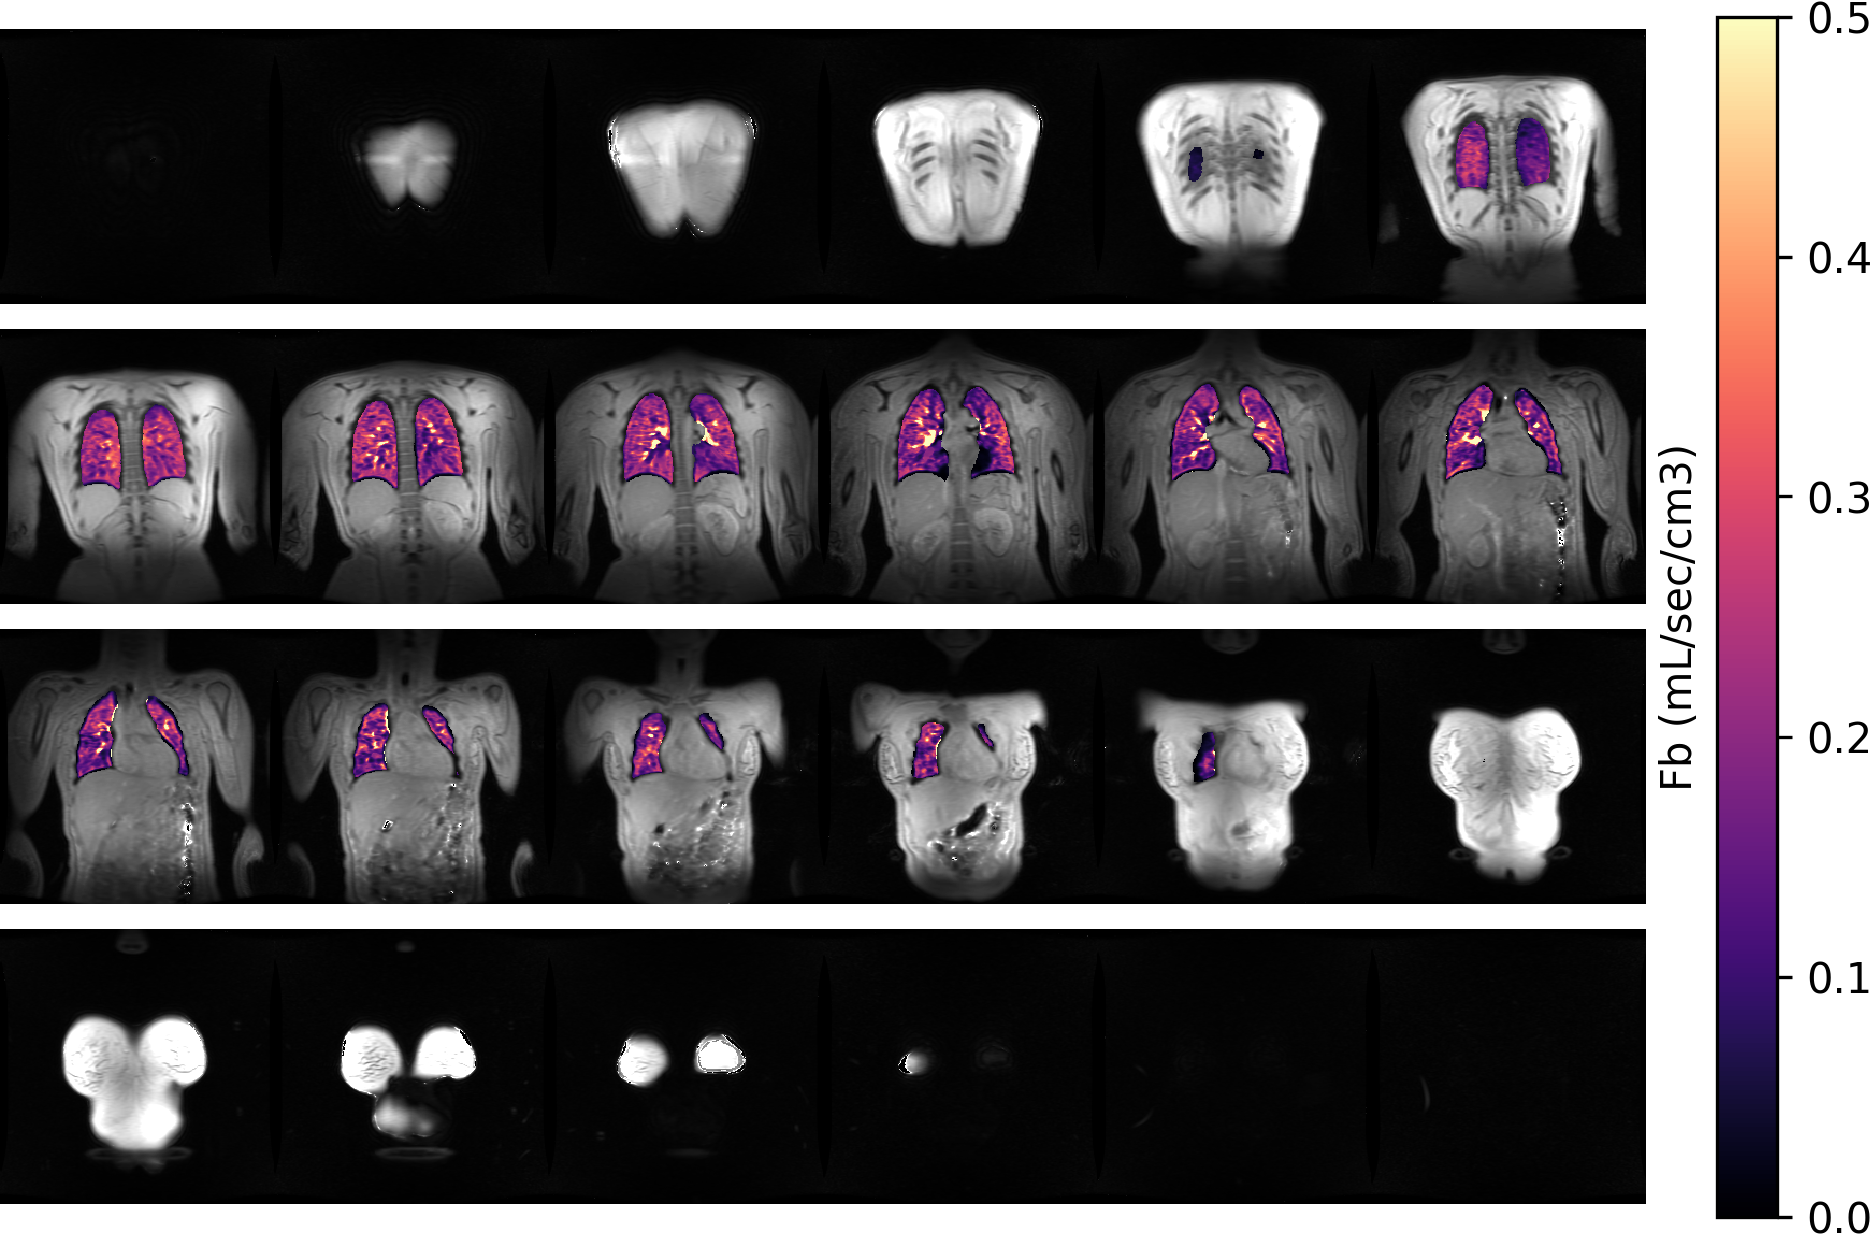

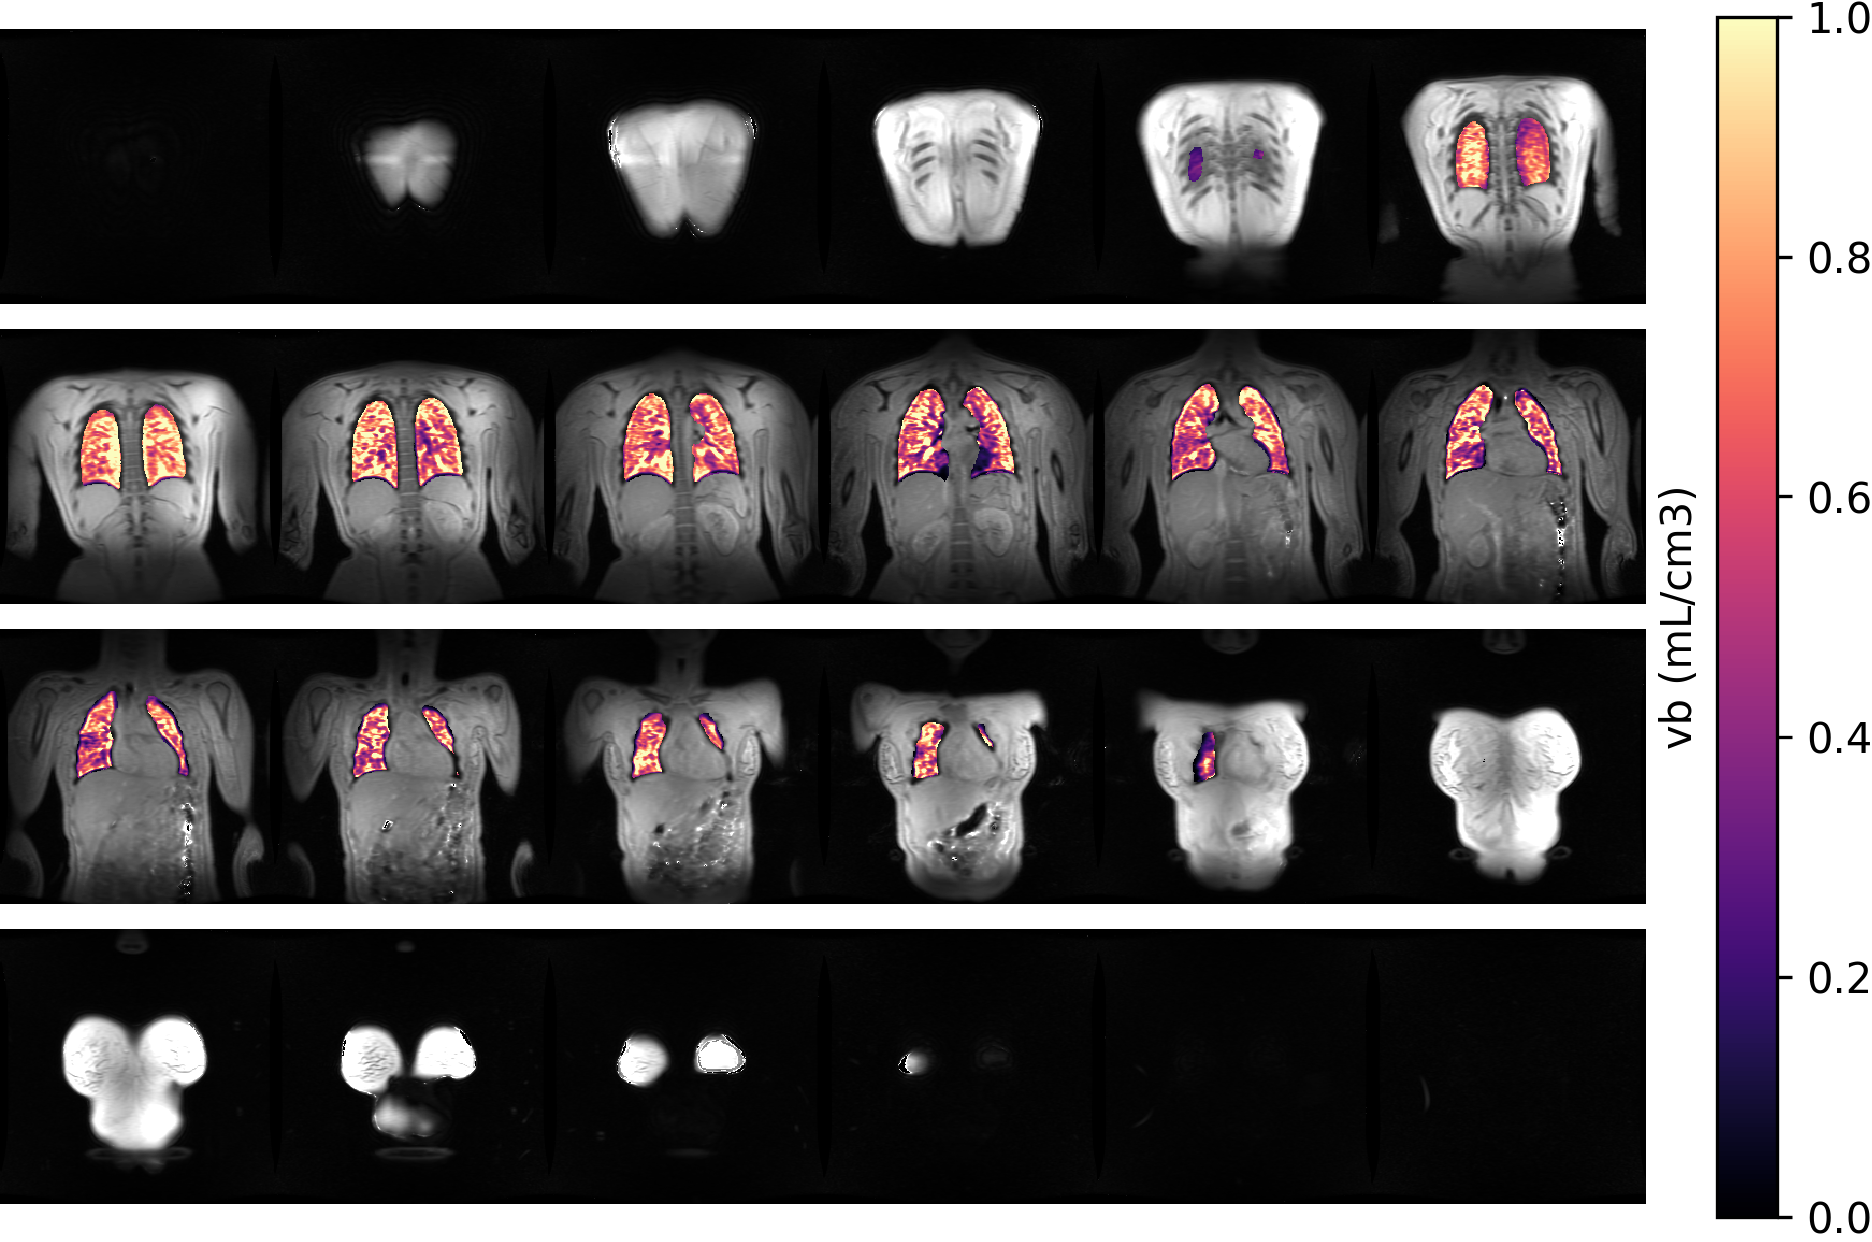

In [4]:
from case_studies.lung_dce import view_png

png = os.path.join(IMAGEPATH, f'Fb_model_based.png')
view_png(png)
png = os.path.join(IMAGEPATH, f'vb_model_based.png')
view_png(png)

# Step 6: Export imaging biomarkers

In [ ]:
from case_studies.lung_dce import pixel_averages_model_based

pixel_averages_model_based(MAPS, MASKS, SUBJ, BUILD_PATH)